# Seleksi Fitur dengan Recursive Feature Elimination (RFE)

Dataset: `Dataset_Latihan_Preprocessing.csv`
Target: `churn_3bln` (1 = churn, 0 = tidak churn)

RFE adalah metode seleksi fitur jenis *wrapper*, artinya pemilihan fitur dilakukan dengan bantuan model. Di notebook ini modelnya **Logistic Regression**.

Cara kerja RFE:
1. Latih model dengan semua fitur.
2. Lihat nilai mutlak koefisien tiap fitur ($|coef|$). Fitur dengan $|coef|$ paling kecil dianggap paling lemah.
3. Buang 1 fitur paling lemah (`step=1`).
4. Ulangi sampai tersisa 6 fitur (`n_features_to_select=6`).

Bedanya dengan Information Gain dan Chi-Square: RFE menilai fitur **secara bersamaan** di dalam satu model, bukan satu per satu.

Langkah-langkah:
1. Load data
2. Preprocessing
3. Jalankan RFE
4. Tabel peringkat RFE
5. Cek fitur `rata_nilai_transaksi_rp`
6. Visualisasi
7. Evaluasi model
8. Simpan dataset
9. Kesimpulan

### 1. Load Library dan Dataset

In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, roc_auc_score
import matplotlib.pyplot as plt

df = pd.read_csv('Dataset_Latihan_Preprocessing.csv')
print(f"Dataset berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom.")
df.head()

Dataset berhasil dimuat: 1000 baris, 22 kolom.


,id_pelanggan,usia_tahun,kota,kanal_akuisisi,tingkat_member,metode_pembayaran,langganan_newsletter,lama_member_bulan,jumlah_transaksi_6bln,rata_nilai_transaksi_rp,...,jumlah_keluhan_6bln,skor_kepuasan,persen_diskon_rata,jumlah_kunjungan_30hari,pengeluaran_bulanan_rp,kode_acak,warna_favorit,negara,kolom_hampir_kosong,churn_3bln
0,PLG0001,34.0,Jakarta,Iklan,Silver,Transfer Bank,Ya,33.0,7.0,280000.0,...,0.0,8.6,29.1,5.0,3380000.0,4262,Biru,Indonesia,NaN,0
1,PLG0002,43.0,Yogyakarta,Marketplace,Gold,E-Wallet,Tidak,15.0,11.0,226000.0,...,NaN,7.6,20.5,14.0,3260000.0,8377,Kuning,Indonesia,NaN,0
2,PLG0003,27.0,Jakarta,Iklan,Bronze,Kartu Kredit,Ya,13.0,9.0,431000.0,...,0.0,10.0,2.1,11.0,5070000.0,7000,Kuning,Indonesia,A,0
3,PLG0004,57.0,Jakarta,Referral,Platinum,COD,Ya,6.0,11.0,324000.0,...,0.0,NaN,29.8,NaN,2740000.0,7210,Kuning,Indonesia,NaN,0
4,PLG0005,27.0,Surabaya,Organik,Silver,Transfer Bank,Tidak,28.0,6.0,NaN,...,0.0,NaN,13.9,5.0,2150000.0,3037,Hijau,Indonesia,NaN,0


**Penjelasan:**

Dataset punya 1000 baris dan 22 kolom (21 fitur + 1 target). Karena RFE melatih model Logistic Regression, data harus berupa angka semua dan tidak boleh ada nilai kosong. Padahal di data ini masih ada kolom teks (`kota`, `tingkat_member`, dll) dan nilai `NaN`, jadi perlu preprocessing dulu.

### 2. Preprocessing

1. **Buang `id_pelanggan`**, karena ID unik tidak bisa dipakai untuk memprediksi pelanggan baru dan hanya membuat model menghafal data.
2. **Isi nilai kosong**:
   - Kolom numerik diisi dengan **median**, bukan mean. Data ini banyak outlier (misalnya `total_belanja_6bln_rp` sampai 600 juta), dan mean mudah tertarik oleh outlier, sedangkan median tidak.
   - Kolom kategorikal diisi dengan kategori `'Missing'`.
3. **Encoding kategorikal dengan `OrdinalEncoder`**, yang mengubah tiap kategori menjadi angka 0, 1, 2, dst. One-Hot Encoding tidak dipakai supaya satu kolom tetap jadi satu fitur, jadi RFE menilai kolom `kota` secara utuh, bukan `kota_Jakarta`, `kota_Bandung`, dst. Catatan: `OrdinalEncoder` mengurutkan kategori **berdasarkan abjad**, bukan berdasarkan makna.
4. **Standarisasi dengan `StandardScaler`** (mean = 0, std = 1). RFE memilih fitur dari besar koefisien, jadi semua fitur harus berskala sama. Tanpa scaling, fitur dalam rupiah (jutaan) dan fitur skor (0-10) koefisiennya tidak bisa dibandingkan.

In [2]:
df_clean = df.drop(columns=['id_pelanggan']).copy()

cat_cols = ['kota', 'kanal_akuisisi', 'tingkat_member', 'metode_pembayaran',
            'langganan_newsletter', 'warna_favorit', 'negara', 'kolom_hampir_kosong']
num_cols = [c for c in df_clean.columns if c not in cat_cols and c != 'churn_3bln']

for c in cat_cols:
    df_clean[c] = OrdinalEncoder().fit_transform(df_clean[[c]].fillna('Missing').astype(str)).ravel()
for c in num_cols:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())

X = df_clean.drop(columns=['churn_3bln'])
y = df_clean['churn_3bln']

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

print(f"Jumlah fitur        : {X_scaled.shape[1]} ({len(num_cols)} numerik, {len(cat_cols)} kategorikal)")
print(f"Jumlah baris        : {X_scaled.shape[0]}")
print(f"Sisa nilai kosong   : {X_scaled.isnull().sum().sum()}")
print(f"Rata-rata semua fitur setelah scaling: {X_scaled.mean().abs().max():.2f}")
print(f"Std semua fitur setelah scaling      : {X_scaled.std(ddof=0).round(2).unique()}")

# Contoh hasil encoding tingkat_member (urutan abjad)
enc = OrdinalEncoder().fit(df[['tingkat_member']].fillna('Missing').astype(str))
print("\nUrutan encoding tingkat_member:", dict(zip(enc.categories_[0], range(len(enc.categories_[0])))))

Jumlah fitur        : 20 (12 numerik, 8 kategorikal)
Jumlah baris        : 1000
Sisa nilai kosong   : 0
Rata-rata semua fitur setelah scaling: 0.00
Std semua fitur setelah scaling      : [1. 0.]

Urutan encoding tingkat_member: {'Bronze': 0, 'Gold': 1, 'Missing': 2, 'Platinum': 3, 'Silver': 4}


**Penjelasan:**

- Sekarang ada 20 fitur (12 numerik + 8 kategorikal), 1000 baris, dan tidak ada nilai kosong lagi.
- Setelah scaling, semua fitur rata-ratanya 0 dan standar deviasinya 1. Satu fitur std-nya 0, yaitu `negara`, karena isinya hanya satu nilai.
- Urutan encoding `tingkat_member` mengikuti abjad: Bronze = 0, Gold = 1, Missing = 2, Platinum = 3, Silver = 4. Urutan ini **tidak sesuai** tingkatan member yang sebenarnya (Bronze < Silver < Gold < Platinum). Ini perlu diingat waktu membaca hasil RFE nanti.

### 3. Jalankan RFE

Estimator: `LogisticRegression(max_iter=1000, random_state=42)`, target 6 fitur, dan setiap iterasi membuang 1 fitur (`step=1`).

In [3]:
base_model = LogisticRegression(max_iter=1000, random_state=42)
rfe = RFE(estimator=base_model, n_features_to_select=6, step=1)
rfe.fit(X_scaled, y)

print(f"Jumlah fitur awal   : {X_scaled.shape[1]}")
print(f"Jumlah fitur akhir  : {rfe.n_features_}")
print(f"Jumlah iterasi      : {X_scaled.shape[1] - rfe.n_features_} (1 fitur dibuang per iterasi)")

Jumlah fitur awal   : 20
Jumlah fitur akhir  : 6
Jumlah iterasi      : 14 (1 fitur dibuang per iterasi)


**Penjelasan:**

RFE mulai dari 20 fitur dan membuang 1 fitur di setiap iterasi, jadi butuh 14 iterasi sampai tersisa 6 fitur. Di setiap iterasi model Logistic Regression dilatih ulang, sehingga koefisien fitur yang tersisa ikut berubah. Inilah bedanya dengan metode filter: nilai sebuah fitur bergantung pada fitur lain yang masih ada di dalam model.

### 4. Tabel Peringkat RFE

- `ranking_ = 1` berarti fitur terpilih (bertahan sampai akhir).
- `ranking_ = 2` adalah fitur terakhir yang dibuang, dan seterusnya. Makin besar angkanya, makin awal fitur itu dibuang.
- Kolom `Koefisien` adalah koefisien model akhir (hanya untuk fitur terpilih). Tanda positif berarti menaikkan peluang churn, negatif berarti menurunkan.

In [4]:
koef_akhir = dict(zip(X.columns[rfe.support_], rfe.estimator_.coef_[0]))

df_ranking = pd.DataFrame({
    'Nama Fitur': X.columns,
    'Peringkat RFE': rfe.ranking_,
    'Terpilih': rfe.support_,
    'Koefisien': [round(koef_akhir[c], 3) if c in koef_akhir else None for c in X.columns],
}).sort_values(by='Peringkat RFE').reset_index(drop=True)
df_ranking

,Nama Fitur,Peringkat RFE,Terpilih,Koefisien
0,tingkat_member,1,True,-0.160
1,jumlah_transaksi_6bln,1,True,-0.226
2,hari_sejak_transaksi_terakhir,1,True,1.224
3,rata_nilai_transaksi_rp,1,True,-0.210
4,skor_kepuasan,1,True,-0.818
5,jumlah_keluhan_6bln,1,True,0.777
6,usia_tahun,2,False,NaN
7,kolom_hampir_kosong,3,False,NaN
8,lama_member_bulan,4,False,NaN
9,kanal_akuisisi,5,False,NaN


**Penjelasan:**

- **6 fitur terpilih**: `hari_sejak_transaksi_terakhir`, `skor_kepuasan`, `jumlah_keluhan_6bln`, `jumlah_transaksi_6bln`, `rata_nilai_transaksi_rp`, dan `tingkat_member`.
- Arah koefisiennya masuk akal untuk 4 fitur pertama:
  - `hari_sejak_transaksi_terakhir` (+1,224): makin lama tidak transaksi, makin besar peluang churn. Koefisiennya paling besar.
  - `jumlah_keluhan_6bln` (+0,777): makin banyak keluhan, makin besar peluang churn.
  - `skor_kepuasan` (−0,818): makin puas, makin kecil peluang churn.
  - `jumlah_transaksi_6bln` (−0,226): makin sering transaksi, makin kecil peluang churn.
- Dua fitur lainnya, `rata_nilai_transaksi_rp` dan `tingkat_member`, perlu dicek lagi. Di Information Gain dan Chi-Square keduanya termasuk fitur yang lemah, dan encoding `tingkat_member` juga tidak sesuai urutan aslinya. `rata_nilai_transaksi_rp` dicek di langkah berikutnya.
- `jumlah_kunjungan_30hari` dan `total_belanja_6bln_rp`, yang terpilih di IG dan Chi-Square, di RFE ada di peringkat 8 dan 9.
- `negara` dibuang paling awal (peringkat 15) karena nilainya sama semua, jadi koefisiennya 0.

### 5. Cek Fitur `rata_nilai_transaksi_rp`

Fitur ini terpilih oleh RFE, padahal di metode filter hasilnya lemah. Di sini dicek apakah ada outlier yang memengaruhi koefisiennya.

In [5]:
kolom = 'rata_nilai_transaksi_rp'
print("8 nilai terbesar:")
display(df.nlargest(8, kolom)[[kolom, 'churn_3bln']])

print("Persentase churn per kuartil:")
churn_per_kuartil = df.groupby(pd.qcut(df[kolom], 4), observed=True)['churn_3bln'].mean().mul(100).round(1)
print(churn_per_kuartil.to_string())

8 nilai terbesar:


,rata_nilai_transaksi_rp,churn_3bln
45,40000000.0,0
44,35000000.0,0
43,30000000.0,0
42,25000000.0,0
41,20000000.0,0
40,15000000.0,0
894,1659000.0,0
179,1291000.0,1


Persentase churn per kuartil:
rata_nilai_transaksi_rp
(50999.999, 183000.0]     22.7
(183000.0, 266500.0]      26.5
(266500.0, 388000.0]      28.0
(388000.0, 40000000.0]    20.3


**Penjelasan:**

- Ada 6 nilai ekstrem (15 juta sampai 40 juta rupiah), padahal 99% data di bawah ±1,1 juta. Keenam pelanggan ini **semuanya tidak churn**.
- Kalau dilihat per kuartil, persentase churn naik-turun di sekitar 20-28% tanpa pola yang jelas. Artinya, untuk sebagian besar pelanggan, fitur ini sebenarnya tidak berhubungan dengan churn.
- Koefisien negatif fitur ini kemungkinan besar terbentuk karena 6 outlier tersebut. Logistic Regression sensitif terhadap outlier, apalagi setelah `StandardScaler` (yang juga dihitung dari mean dan std, sehingga ikut terpengaruh outlier).
- Jadi terpilihnya `rata_nilai_transaksi_rp` lebih karena outlier, bukan karena pola yang kuat. Supaya hasil RFE lebih bisa dipercaya, outlier sebaiknya ditangani dulu (misalnya di-clip atau pakai `RobustScaler`).

### 6. Visualisasi

Grafik peringkat RFE. Hijau = fitur terpilih (peringkat 1), abu-abu = fitur yang dibuang. Makin panjang batang, makin awal fitur dibuang.

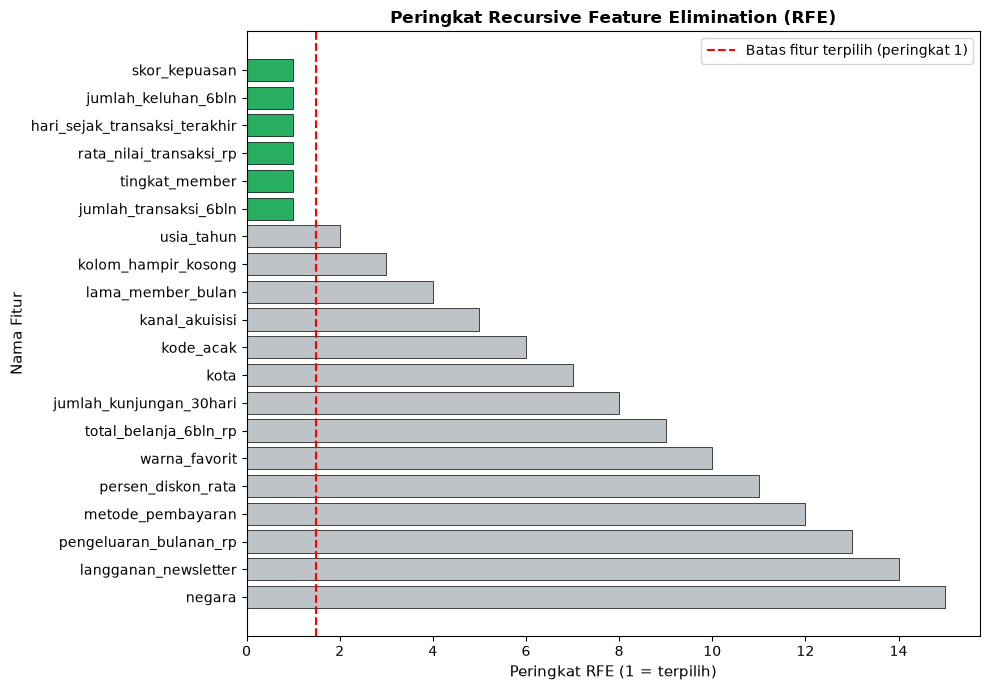

In [6]:
df_plot = df_ranking.sort_values(by='Peringkat RFE', ascending=False)
warna = ['#27ae60' if s else '#bdc3c7' for s in df_plot['Terpilih']]

plt.figure(figsize=(10, 7))
plt.barh(df_plot['Nama Fitur'], df_plot['Peringkat RFE'], color=warna, edgecolor='black', linewidth=0.5)
plt.axvline(x=1.5, color='red', linestyle='--', label='Batas fitur terpilih (peringkat 1)')
plt.title('Peringkat Recursive Feature Elimination (RFE)', fontsize=12, fontweight='bold')
plt.xlabel('Peringkat RFE (1 = terpilih)', fontsize=11)
plt.ylabel('Nama Fitur', fontsize=11)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

**Penjelasan:**

Enam batang hijau di bagian atas adalah fitur terpilih. Batang abu-abu menunjukkan urutan fitur yang dibuang: `usia_tahun` (peringkat 2) adalah fitur terakhir yang dibuang, sedangkan `negara` (peringkat 15) dibuang paling awal. Berbeda dari IG dan Chi-Square, panjang batang di sini hanya urutan, bukan skor, jadi jarak antar batang tidak menunjukkan seberapa besar perbedaan kekuatan fiturnya.

### 7. Evaluasi Model: 20 Fitur vs 6 Fitur RFE

Model Logistic Regression dibandingkan dengan dua cara:
- **Data training**: model dilatih dan dites di data yang sama (hasilnya cenderung terlalu bagus).
- **5-Fold Cross Validation**: data dibagi 5 bagian, model dilatih di 4 bagian dan dites di 1 bagian, diulang 5 kali. Hasil ini lebih menggambarkan performa di data baru.

In [7]:
fitur_terpilih = X.columns[rfe.support_].tolist()
skenario = {'Semua fitur (20)': list(X.columns), 'Fitur RFE (6)': fitur_terpilih}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

hasil = []
for nama, cols in skenario.items():
    model = LogisticRegression(max_iter=1000, random_state=42).fit(X_scaled[cols], y)
    hasil.append({
        'Skenario': nama,
        'Akurasi train (%)': round(accuracy_score(y, model.predict(X_scaled[cols])) * 100, 2),
        'ROC-AUC train': round(roc_auc_score(y, model.predict_proba(X_scaled[cols])[:, 1]), 4),
        'Akurasi CV (%)': round(cross_val_score(LogisticRegression(max_iter=1000, random_state=42),
                                                X_scaled[cols], y, cv=cv, scoring='accuracy').mean() * 100, 2),
        'ROC-AUC CV': round(cross_val_score(LogisticRegression(max_iter=1000, random_state=42),
                                           X_scaled[cols], y, cv=cv, scoring='roc_auc').mean(), 4),
    })
pd.DataFrame(hasil)

,Skenario,Akurasi train (%),ROC-AUC train,Akurasi CV (%),ROC-AUC CV
0,Semua fitur (20),83.6,0.8448,82.3,0.8281
1,Fitur RFE (6),82.2,0.8382,82.3,0.8339


**Penjelasan:**

- Di **data training**, model 20 fitur sedikit lebih bagus (akurasi 83,6% vs 82,2%). Ini wajar, karena model dengan fitur lebih banyak selalu bisa lebih "pas" dengan data latihnya.
- Di **cross validation**, akurasinya sama (82,3%), dan ROC-AUC model 6 fitur malah sedikit lebih tinggi (0,8339 vs 0,8281). Artinya 14 fitur yang dibuang tidak membantu prediksi di data baru, dan justru sedikit menambah noise.
- Kesimpulannya, dengan membuang 14 dari 20 fitur (70%), performa model tidak turun. Model jadi lebih sederhana tanpa kehilangan kemampuan prediksi.
- Catatan: RFE dan scaler dijalankan di seluruh data sebelum cross validation, jadi hasil CV masih sedikit optimis.

### 8. Simpan Dataset

Dataset dengan 6 fitur terpilih (nilai asli, belum di-encode atau di-scaling) disimpan ke `Dataset_Hasil_Seleksi_RFE.csv`.

In [8]:
df_final = df[fitur_terpilih + ['churn_3bln']].copy()
df_final.to_csv('Dataset_Hasil_Seleksi_RFE.csv', index=False)

print("Fitur terpilih:")
for i, f in enumerate(fitur_terpilih, 1):
    print(f"  {i}. {f}")
print(f"\nDataset disimpan ke 'Dataset_Hasil_Seleksi_RFE.csv' dengan dimensi {df_final.shape}.")

Fitur terpilih:
  1. tingkat_member
  2. jumlah_transaksi_6bln
  3. rata_nilai_transaksi_rp
  4. hari_sejak_transaksi_terakhir
  5. jumlah_keluhan_6bln
  6. skor_kepuasan

Dataset disimpan ke 'Dataset_Hasil_Seleksi_RFE.csv' dengan dimensi (1000, 7).


**Penjelasan:**

Dataset baru berukuran (1000, 7): 6 fitur + target. Yang disimpan adalah nilai asli dari data mentah, jadi masih ada nilai kosong, outlier, dan kolom teks (`tingkat_member`). Preprocessing perlu dilakukan lagi sebelum data dipakai untuk training model.

### 9. Kesimpulan

- RFE memilih 6 fitur: `hari_sejak_transaksi_terakhir`, `skor_kepuasan`, `jumlah_keluhan_6bln`, `jumlah_transaksi_6bln`, `rata_nilai_transaksi_rp`, dan `tingkat_member`.
- Empat fitur pertama sama dengan hasil Information Gain dan Chi-Square, dan arah koefisiennya masuk akal.
- `rata_nilai_transaksi_rp` terpilih karena pengaruh 6 outlier, dan `tingkat_member` di-encode dengan urutan abjad, jadi dua fitur ini perlu dicek ulang.
- Model dengan 6 fitur performanya setara dengan model 20 fitur.

Kekurangan RFE:
1. Hasilnya bergantung pada model yang dipakai. Logistic Regression hanya menangkap hubungan linear dan sensitif terhadap outlier.
2. Hasilnya juga bergantung pada preprocessing (cara imputasi, encoding, dan scaling).
3. Jumlah fitur (6) harus ditentukan sendiri. Untuk mencari jumlah terbaik secara otomatis bisa pakai `RFECV`.
4. Lebih lambat dari metode filter karena model dilatih berulang kali.